# Урок 12. Как у мягкого шарика появляются собственные оси

[Программа курса](../../README_ru.md)

У точки из прошлого урока нет ширины. Из любого положения камеры она даёт один адрес. Теперь вокруг неё появится мягкое облачко. На равном весе у круглого облачка получится сфера. Если потянуть его за один край и повернуть целиком, та же линия равного веса превратится в поверхность вытянутого эллипсоида.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. Три размера одного облачка

Оба рисунка показывают одну проволочную поверхность. Справа мы смотрим вдоль $z$, слева — под углом. Это пока чертежи без перспективы. Цветные отрезки идут из центра до поверхности вдоль её собственных осей. У оранжевого сначала длина 2 м, у зелёного 0.75 м, у фиолетового 1 м. Когда угол меняется, концы отрезков переезжают. Их длины сохраняются.

При трёх одинаковых масштабах получается шар. Можно развернуть его на любой угол: цветные отрезки повернутся, геометрический контур совпадёт с прежним. Если один масштаб длиннее, только некоторые повороты сохранят силуэт. Вес в чёрной метке позволяет отличить эти случаи одним числом.

In [2]:
display(demos.geometry_lab(12, "ru"))

У чёрной метки другая роль. Её можно перемещать вдоль мировой оси $x$, независимо от поворота оболочки. Оставим метку в $(1.5,0,0)$ м. При нулевом угле длинная ось проходит через метку, и та находится внутри сетки. При повороте на четверть круга через неё проходит короткая ось, и сетка до неё уже не дотягивается. Цветной отрезок всегда связан с формой. Чёрная метка связана со столом. Когда фигура поворачивается, меняется вес в одном и том же месте пространства. Этот вес можно предсказать до поворота.

## 2. По какой дороге идти от центра

Начнём с круглого облачка с тремя масштабами по метру. Вправо на метр, вниз на метр и вперёд на метр — три разных поездки **из центра**, в конце каждой получается один и тот же вес. Есть и четвёртая поездка: 0.6 м вправо, затем 0.8 м вниз. Фактическое удаление от центра равно $\sqrt{0.6^2+0.8^2}=1$ м. Через каждую из четырёх конечных точек проходит одна сфера. Сама траектория поездки в расчёт веса не входит, он зависит от положения её конца.

Потянем облачко вдоль $x$ вдвое. Материальная метка, которая раньше была на поверхности в $(1,0,0)$, окажется в $(2,0,0)$. Зато в прежней неподвижной точке $(1,0,0)$ относительное удаление теперь только $1/2$: та же точка стола стала ближе к центру в единицах новой ширины. По $y$ сделаем обратное, сожмём масштаб до $0.75$ м. Своя единица там закончится раньше, чем метр линейки. По $z$ оставим прежний метр. Для вычисления веса в произвольной точке теперь нужны три разных деления.

## 3. Как вычислить вес и нарисовать поверхность

Пока оси совпадают с мировыми. Пусть центр $\mu=(0,0,0)$ м, а масштабы $s_x=2$, $s_y=0.75$, $s_z=1$ м. По каждой оси мы сначала вычитаем центр и делим на **её** масштаб. Для точки $(2,0,0)$ получатся числа $(2/2,0/0.75,0/1)=(1,0,0)$, уже без единиц. Для $(0,0.75,0)$ выйдет $(0,1,0)$. В обоих случаях сумма квадратов равна 1. Значит, вес из урока 3 совпадает, хотя расстояния в метрах разные:

$$
D^2=h_x^2+h_y^2+h_z^2,\qquad G=\exp(-D^2/2)=\exp(-1/2)\approx0.607.
$$

Здесь $h$ — три относительных смещения, $D^2$ измеряет квадрат удалённости в масштабе облачка, а $G$ — относительный вес с максимумом 1 в центре. Рисунок соединяет только точки $D^2=1$. За проволокой вес продолжает убывать; жёсткой границы у облачка нет.

Для построения поверхности расчёт удобно обратить. На единичной сфере берём точку $h=(0.6,0.8,0)$, ведь $0.6^2+0.8^2=1$. По своим осям умножаем на масштабы: $(1.2,0.6,0)$ м. Затем следует поворот $R$, и уже после него добавляется центр. Короткая запись $P=\mu+RSh$ использует диагональную матрицу $S$. По диагонали стоят три масштаба, все остальные числа нули. Умножение на неё как раз даёт $(s_x h_x,s_y h_y,s_z h_z)$.

In [3]:
scales = np.array([2., .75, 1.])
h = np.array([.6, .8, 0.])
print("Sh =", scales*h, "m; G =", np.exp(-(h @ h)/2))
assert np.isclose(h @ h, 1)

Sh = [1.2 0.6 0. ] m; G = 0.6065306597126334


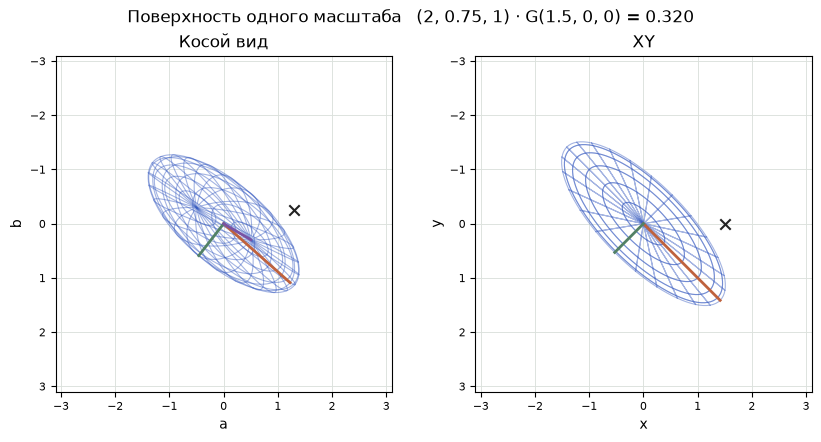

In [4]:
fig = demos.ellipsoid_figure("ru")
plt.show()

## 4. Фиксированная метка и две разные задачи

Пусть у фигуры уже есть поворот $R$, а её центр мы перенесли в $\mu=(3,-1,4)$ м. Для построения сетки известна точка на единичной сфере и неизвестен её мировой адрес. Сначала растягиваем её по собственным осям, затем поворачиваем, затем прибавляем центр. Например, $h=(0.6,0.8,0)$ после растяжения стал $(1.2,0.6,0)$. Поворот на $90^\circ$ вокруг $z$ переводит прежнюю правую ось в направление $+y$, а прежнюю нижнюю в $-x$. Получится $(-0.6,1.2,0)$; после переноса мировой адрес равен $(2.4,0.2,4)$ м.

При рисовании кадра вопрос часто идёт **в обратную сторону**. Уже известна точка $P=(2.4,0.2,4)$ мира. Насколько близко к центру гауссианы она оказалась? Отнимаем $\mu$ и возвращаемся к $(-0.6,1.2,0)$. Поворот назад переводит это в $(1.2,0.6,0)$ в собственных осях. Только теперь делим компоненты на $(2,0.75,1)$, получаем $(0.6,0.8,0)$. После сложения квадратов возвращается единица. Если сразу делить мировое горизонтальное смещение на длинный масштаб 2, то форма останется для расчёта горизонтальной и не будет следовать за своим же рисунком.

Чёрная метка в опыте позволяет поймать такую ошибку без переноса центра. У $\mu=(0,0,0)$ и $P=(1.5,0,0)$ при нулевом угле $D^2=(1.5/2)^2=0.5625$, вес $\exp(-0.5625/2)\approx0.755$. При $90^\circ$ смещение в собственных осях равно $(0,-1.5,0)$. Тогда $D^2=(-1.5/0.75)^2=4$, вес $\exp(-2)\approx0.135$. Расстояние между меткой и центром в метрах оба раза 1.5. Поменялось то, какая ширина лежит вдоль этого расстояния. Для шара с тремя одинаковыми масштабами этот опыт дал бы горизонтальную линию веса при любом повороте.

In [5]:
mark = np.array([1.5, 0., 0.])
for degrees in [0, 45, 90]:
    q = geo.axis_angle_quaternion([0,0,1], degrees)
    local = geo.quaternion_matrix(q).T @ mark
    h_probe = local / scales
    d2 = h_probe @ h_probe
    cov = geo.covariance_3d(scales, q)
    np.testing.assert_allclose(d2, mark @ np.linalg.solve(cov, mark))
    print(f"{degrees:2}°  local = {np.round(local,4)}  D² = {d2:.4f}  G = {np.exp(-d2/2):.4f}")

 0°  local = [1.5 0.  0. ]  D² = 0.5625  G = 0.7548
45°  local = [ 1.0607 -1.0607  0.    ]  D² = 2.2813  G = 0.3196
90°  local = [ 0.  -1.5  0. ]  D² = 4.0000  G = 0.1353


## 5. Ось, угол и четыре числа поворота

Ось поворота — стрелка, которая при повороте остаётся на месте. Вокруг $z$ поворот на $90^\circ$ переносит правое направление $(1,0,0)$ в нижнее $(0,1,0)$. Три столбца $R$ — новые положения старых осей. Для этого поворота они равны $(0,1,0)$, $(-1,0,0)$ и $(0,0,1)$. Уже этого достаточно, чтобы умножать $R$ на любую точку.

Для обучения удобно хранить поворот четырьмя числами — **кватернионом**. Здесь их порядок $q=(w,x,y,z)$, скалярная часть первая. Эти $x,y,z$ принадлежат записи поворота и не задают положение центра. Если ось дана стрелкой $a=(0,0,2)$, сначала делим её на длину $\sqrt{0^2+0^2+2^2}=2$. Получается единичная ось $n=(0,0,1)$. Нулевая стрелка не задаёт направления. Из оси и угла $\theta$ строятся

$$
w=\cos(\theta/2),\qquad (x,y,z)=n\sin(\theta/2).
$$

Для $\theta=90^\circ$ в половине угла $45^\circ$. Косинус и синус равны $\sqrt{2}/2\approx0.7071$. Выходит $q=(0.7071,0,0,0.7071)$. Квадраты четырёх чисел в сумме дают 1. Если при обучении пришло $(2,0,0,2)$, перед поворотом все компоненты делятся на длину $\sqrt{2^2+2^2}=\sqrt{8}$. Получается та же единичная четвёрка. Для $(0,0,0,0)$ делить не на что.

Почему угол делится пополам? Для оси $z$ действие на правую единичную стрелку записывается как $(w^2-z^2,\,2wz,\,0)$. Пусть $w=\cos t$ и $z=\sin t$. Тогда по формулам двойного угла это $(\cos(2t),\sin(2t),0)$ — поворот уже на $2t$. Чтобы получить угол $\theta$, в запись кладут $t=\theta/2$. В нашем примере даётся $(0.5-0.5,\;2\cdot0.7071^2,\;0)\approx(0,1,0)$, как в чертеже.

In [6]:
q = geo.axis_angle_quaternion([0,0,2], 90)
R = geo.quaternion_matrix(q)
print("q =", q, "\nR =\n", R, "\nR (1,0,0) =", R @ [1,0,0])
np.testing.assert_allclose(R, geo.quaternion_matrix([2,0,0,2]), atol=1e-14)

q = [0.7071 0.     0.     0.7071] 
R =
 [[ 0. -1.  0.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]] 
R (1,0,0) = [0. 1. 0.]


## 6. Что означают числа готовой матрицы поворота

Для поворота вокруг $z$ почти всё видно в плоскости $xy$. Как проверить строку большой формулы для наклонной оси? Возьмём ось $(1,1,1)$ и поворот на треть оборота, $120^\circ$. Эта ось идёт по диагонали куба из одного угла в противоположный. Три выходящих из угла ребра симметричны вокруг неё. После трети оборота их направления циклически поменяются местами. Измерим, в какую сторону пойдёт первый переход, и заодно получим простой тест на порядок четырёх чисел.

У оси длина $\sqrt{3}$, поэтому единичные компоненты равны $1/\sqrt{3}$. Половина угла равна $60^\circ$. Косинус даёт $w=1/2$, синус равен $\sqrt{3}/2$. Для каждой векторной компоненты получаем $(1/\sqrt{3})(\sqrt{3}/2)=1/2$. Четвёрка $q=(0.5,0.5,0.5,0.5)$ уже нормирована: сумма квадратов равна $4\cdot0.25=1$. У всех попарных произведений одно значение, $0.25$, поэтому строки формулы ниже считаются без приближений.

Посчитаем первый столбец сверху вниз. Первая координата равна $1-2(0.25+0.25)=0$, вторая — $2(0.25+0.25)=1$, третья — $2(0.25-0.25)=0$. Получился вектор $(0,1,0)$. Так переместился конец первой единичной оси. Из второго столбца выходит $(0,0,1)$, из третьего $(1,0,0)$. В частности, точка с локальным смещением $(2,0,0)$ после поворота получает мировое смещение $(0,2,0)$. Смещение $(1,1,1)$ при перестановке вообще не изменится: оно лежит на оси поворота. Повернуть весь куб на $120^\circ$ и одновременно оставить одну стрелку неизменной здесь вполне возможно.

Если в файле скалярная часть записана последней, опыт с четырьмя одинаковыми компонентами не выявит перестановки. Её поймает предыдущий поворот на четверть оборота вокруг $z$. При передаче между двумя программами для проверки очень удобны свободная стрелка $(1,0,0)$ и заранее просчитанное ожидаемое направление. Картинка круглого пятна в этой роли бесполезна: поворот внутри сферы вполне может быть неверным, а контур останется тем же.

У повторяющихся квадратов в матрице есть геометрическая причина. Возьмём единичную ось поворота $n=(n_x,n_y,n_z)$ и стрелку вправо $e=(1,0,0)$. Длина её тени на оси равна $e\cdot n=n_x$. Значит, вдоль оси лежит часть $n_x n$, которая при повороте останется на месте. Оставшаяся часть $e-n_x n$ лежит в плоскости поворота. Её конец движется по окружности. Вдоль прежнего радиуса его смещение от центра окружности получает множитель $\cos\theta$, поперёк — множитель $\sin\theta$. Для нашей стрелки поперечное направление с нужной длиной равно $(0,n_z,-n_y)$. Так считается векторное произведение $n\times e$. Оно перпендикулярно обеим стрелкам, а его знак задаёт сторону положительного поворота. Например, при $n=(0,0,1)$ получилось бы $(0,1,0)$, ровно вниз по рисунку.

Сложим только горизонтальные компоненты. От неподвижной части осталось $n_x^2$, от радиуса добавилось $(1-n_x^2)\cos\theta$, у поперечной стрелки горизонтальная компонента нулевая. В сумме получилось $n_x^2+(1-n_x^2)\cos\theta$. У единичной оси $1-n_x^2=n_y^2+n_z^2$. Кроме того, $1-\cos\theta=2\sin^2(\theta/2)$. С этими двумя подстановками сумма принимает вид $1-2(n_y^2+n_z^2)\sin^2(\theta/2)$. В компоненты кватерниона $y$ и $z$ уже вошёл синус половинного угла. Остаётся $1-2(y^2+z^2)$, верхнее левое число в матрице. На следующей строке того же столбца будет вертикальная компонента той же повёрнутой стрелки. Если начать со стрелок вниз и вперёд, получатся остальные два столбца.

In [7]:
q_cube = geo.axis_angle_quaternion([1,1,1],120)
R_cube = geo.quaternion_matrix(q_cube)
expected = [[0,0,1],[1,0,0],[0,1,0]]
print("q =", np.round(q_cube,4), "  R @ [2,0,0] =", np.round(R_cube @ [2,0,0],4))
np.testing.assert_allclose(R_cube, expected, atol=1e-14)
np.testing.assert_allclose(R_cube @ [1,1,1], [1,1,1])

q = [0.5 0.5 0.5 0.5]   R @ [2,0,0] = [ 0.  2. -0.]


## 7. От кватерниона к матрице формы

Для любой единичной четвёрки три новых оси собираются по одним правилам. Первая строка ниже даёт горизонтальные компоненты трёх осей. Чтобы узнать горизонтальную координату повёрнутой точки, каждое число строки умножается на соответствующую координату точки, затем три произведения складываются.

$$
R=\begin{bmatrix}
1-2(y^2+z^2)&2(xy-zw)&2(xz+yw)\\
2(xy+zw)&1-2(x^2+z^2)&2(yz-xw)\\
2(xz-yw)&2(yz+xw)&1-2(x^2+y^2)
\end{bmatrix}.
$$

Здесь $xy$ значит $x\cdot y$. Например, при $q=(\sqrt{2}/2,0,0,\sqrt{2}/2)$ первый элемент равен $1-2(0+1/2)=0$, второй $2(0-1/2)=-1$, третий 0. Отсюда у повёрнутой точки $(1.2,0.6,0)$ горизонтальная координата $0\cdot1.2-1\cdot0.6+0=-0.6$ м. Если поменять знаки сразу у всех четырёх компонентов $q$, все попарные произведения и квадраты останутся прежними. $q$ и $-q$ описывают один поворот.

Масштабы формы положительны. В собственных осях их квадраты стоят на диагонали ковариации: $D=\mathrm{diag}(4,0.5625,1)$ в м². Этот $D$ — матрица, в отличие от скалярной величины $D^2$ в расчёте веса выше. Если из единичной сферы в эллипсоид ведёт $M=RS$, то ковариация меняется с двух сторон: $\Sigma=MM^{\mathsf T}=RDR^{\mathsf T}$. Число $\Sigma_{xy}$ — скалярное произведение первой и второй строк $M$. Оно показывает, насколько одни и те же собственные смещения двигают точку вдоль обеих мировых осей.

Например, при $45^\circ$ вокруг $z$ обозначим $c=\cos45^\circ=s=\sin45^\circ$. Первые две строки $M$ равны $(2c,-0.75s,0)$ и $(2s,0.75c,0)$. Отсюда $\Sigma_{xx}=4c^2+0.5625s^2=2.28125$, $\Sigma_{yy}=2.28125$, а $\Sigma_{xy}=4cs-0.5625sc=1.71875$ м². Удлинение идёт одновременно вправо и вниз, поэтому перекрёстный элемент положителен. При $90^\circ$ он исчезает, а два поперечных квадрата просто меняются местами.

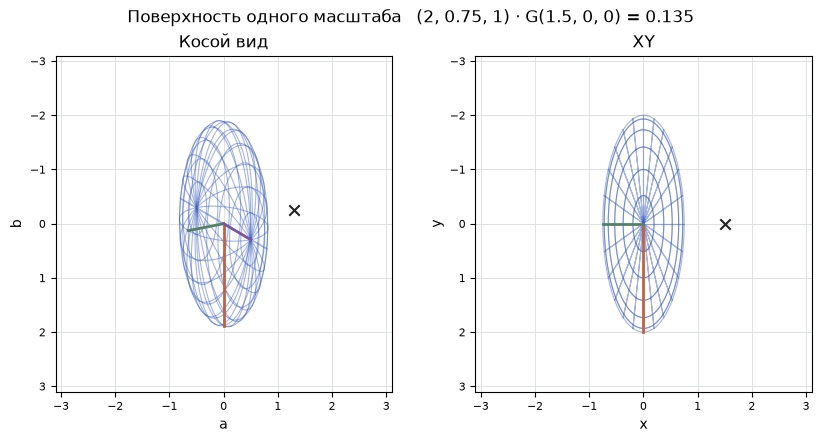

In [8]:
fig = demos.ellipsoid_figure("ru", angle=90)
plt.show()

In [9]:
q45 = geo.axis_angle_quaternion([0,0,1], 45)
cov = geo.covariance_3d(scales, q45)
print("Σ =\n", cov)
delta = geo.quaternion_matrix(q45) @ (scales*h)
relative_squared = delta @ np.linalg.solve(cov, delta)
print("G on shell =", np.exp(-relative_squared/2))
np.testing.assert_allclose(relative_squared, 1)

Σ =
 [[2.2812 1.7188 0.    ]
 [1.7188 2.2813 0.    ]
 [0.     0.     1.    ]]
G on shell = 0.6065306597126333


## 8. Из матрицы обратно в мягкое пятно

В повёрнутом на $45^\circ$ примере диагональные элементы в плоскости равны друг другу. Неужели на рисунке теперь круг? Ответ выдаёт внедиагональное число. Обозначим $a=2.28125$ и $b=1.71875$ м². Действие верхнего левого квадрата ковариации на вектор $(1,1)$ даёт $(a+b,b+a)=(4,4)$; оба числа выросли в четыре раза. Для вектора $(1,-1)$ получится $(a-b,b-a)=(0.5625,-0.5625)$, рост в $0.5625$ раза. Первое направление лежит вдоль длинной диагонали рисунка, второе — поперёк неё. Направления при умножении сохранились, а числа 4 и 0.5625 равны квадратам исходных масштабов.

Так можно прочитать слова **собственное направление** и **собственное значение** ковариации на конкретном эллипсе. Нормируем $(1,1,0)$ до длины один делением на $\sqrt{2}$. Если приложить матрицу к этой единичной стрелке, получится та же стрелка, умноженная на 4 м². Квадратный корень из этого значения даёт длину полуоси 2 м. Для поперечной стрелки выходит $\sqrt{0.5625}=0.75$ м. Третье направление $(0,0,1)$ имеет значение $1$ м². У сферы три числа равны. Тогда по её форме невозможно восстановить, куда при построении смотрела первая локальная ось. Никакая точность вычислений не извлечёт ориентацию из совершенно круглой поверхности.

У чёрной метки при угле $45^\circ$ компоненты смещения в локальной системе равны $(1.5/\sqrt{2},-1.5/\sqrt{2},0)$ м. Деление по осям и сложение квадратов дают

$$
D^2=\frac{1.5^2/2}{2^2}+\frac{1.5^2/2}{0.75^2}
=0.28125+2=2.28125.
$$

Здесь получилось то же число, что у диагонального элемента матрицы, случайно: $D^2$ безразмерно, а у элемента матрицы единицы м². Достаточно сдвинуть метку, чтобы равенство пропало. Вес в этой точке около $0.320$. Тот же расчёт в мировых координатах записывают как $D^2=d^{\mathsf T}\Sigma^{-1}d$, где $d=P-\mu$. Сначала $\Sigma^{-1}$ раскладывает смещение вдоль осей и учитывает обратные **квадраты** ширин; последнее скалярное произведение даёт сумму. В коде система $\Sigma v=d$ решается для $v$, затем вычисляется $d\cdot v$. Отдельно строить обратную матрицу для этого не приходится.

## 9. Проволока, срез и прозрачность

На двух картах показаны параллельные плоскости $xy$ срезы одного и того же облачка. На первом $z=0$, через центр. На втором $z=1$ м, на один масштаб дальше от центра вдоль оси глубины. У каждой точки второго среза к $D^2$ прибавилась единица. Поэтому весь рисунок стал слабее в $\exp(-1/2)\approx0.607$ раза. Центр первого среза имел вес 1, центр второго среза уже 0.607. Единая цветовая шкала делает такое сравнение возможным. Если каждый рисунок отдельно растянуть по яркости до своего максимума, два среза покажутся одинаковыми.

Вес $G$ сам по себе ещё не сообщает цвет пикселя. Земляной комок и дымное пятно могут иметь одинаковую форму срезов и разную непрозрачность. В центре $G=1$ даже у слабого пятна. Если умножить весь пространственный профиль на амплитуду 0.3, в его вершине будет 0.3. На контуре одного масштаба получится $0.3\cdot0.607\approx0.182$. На этих картах мы измеряем пространственный вес в заданной точке. Камера же смотрит вдоль луча и видит на нём сразу множество глубин. Переход от трёхмерной формы к экранному следу заслуживает отдельного разбора в следующем уроке.

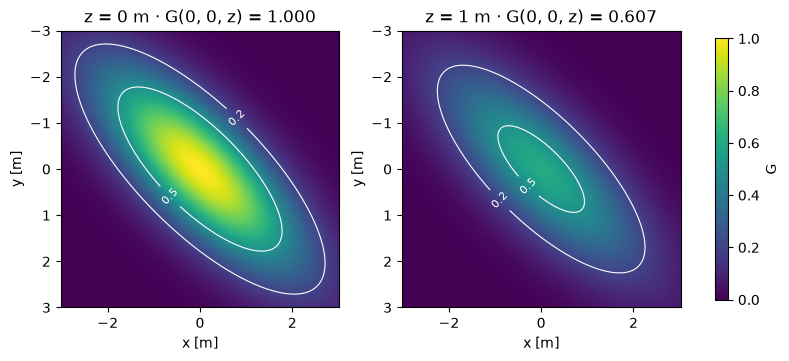

In [10]:
x, y = np.meshgrid(np.linspace(-3,3,151), np.linspace(-3,3,151))
fig, axes = plt.subplots(1,2,figsize=(7.8,3.6),layout="constrained")
rotation = geo.quaternion_matrix(q45)
for ax, z in zip(axes,[0.,1.]):
    offsets = np.stack([x, y, np.full_like(x,z)],axis=-1)
    local = offsets @ rotation
    weight = np.exp(-.5*np.sum((local/scales)**2,axis=-1))
    im = ax.pcolormesh(x,y,weight,shading="auto",vmin=0,vmax=1,cmap="viridis")
    contour = ax.contour(x,y,weight,levels=[.2,.5],colors="white",linewidths=.8)
    ax.clabel(contour,fmt="%.1f",fontsize=8)
    ax.set(xlabel="x [m]",ylabel="y [m]",title=f"z = {z:g} m · G(0, 0, z) = {weight[75,75]:.3f}",
           aspect="equal",ylim=(3,-3))
fig.colorbar(im,ax=list(axes),label="G",shrink=.8)
plt.show()

## 10. Где у формы ломается геометрия

**Опыт.** У эллипсоида масштабы $(2,1,1)$. Сначала он вращается вокруг длинной оси $x$, затем отдельно вокруг $z$. В каком случае силуэт вдоль $z$ изменится?

<details>
<summary>Разбор</summary>

Для первого поворота два поперечных размера совпадают. Их круг можно повернуть без изменения поверхности. Матрица остаётся $\mathrm{diag}(4,1,1)$. Поворот вокруг $z$ на $90^\circ$ переводит длинное направление в $y$ и даёт $\mathrm{diag}(1,4,1)$. Вместо горизонтального эллипса виден вертикальный.

</details>

**Плоское облачко.** Что случится при попытке задать $s_z=0$?

<details>
<summary>Разбор</summary>

Третье смещение придётся делить на ноль. В матрице формы появится направление нулевой ширины, по которому нельзя восстановить исходное смещение. Плоский диск сам по себе осмыслен, но вычисление веса полноценной объёмной гауссианы требует трёх ненулевых масштабов. Поэтому в опыте нижняя граница положительна.

</details>

Та же запись оси и половинного угла приводится в [справке SciPy по кватернионам](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.transform.Rotation.from_quat.html). При обмене данными имеет значение, где находится скалярная часть.

## 11. Проверка формы по нескольким измерениям

**Полоса под другим углом.** Как отличить матрицу с $b=+1.71875$ от матрицы с таким же по модулю отрицательным $b$, измеряя вес только в двух точках относительно центра?

<details>
<summary>Разбор</summary>

Подойдут $(1,1,0)$ и $(1,-1,0)$. При положительном $b$ первая метка лежит вдоль длинной оси, её относительная удалённость меньше, вес больше. При отрицательном $b$ длинная ось повернётся к второй метке. Промеры только на мировых осях $x$ и $y$ такого различия не показывают.
</details>

**Достаточно ли положительной диагонали?** Кандидат на плоский блок ковариации имеет строки $(1,2)$ и $(2,1)$ в м². Какое направление выдаёт ошибку?

<details>
<summary>Разбор</summary>

Умножение на $(1,-1)$ даёт $(-1,1)$, то есть ту же стрелку с множителем $-1$. Это потребовало бы квадрат масштаба $-1$ м². Реального положительного масштаба с таким квадратом нет. Параметры «положительные ширины плюс поворот» автоматически защищают от такой матрицы.
</details>

**Невидимый поворот.** У цветного облачка масштабы $(2,2,0.5)$ м. На сколько изменится вес в фиксированной мировой точке, если повернуть его вокруг собственной короткой оси на $37^\circ$?

<details>
<summary>Разбор</summary>

Вес сохранится. В плоскости первых двух осей знаменатель обоих квадратов равен 4, поэтому в сумму входит $(d_x^2+d_y^2)/4$. Поворот сохраняет сумму двух квадратов, а компонент вдоль оси поворота прежний. По весам этого пятна такой поворот неотличим от нулевого.
</details>